In [ ]:

from pathlib import Path
from zipfile import ZipFile
from google.colab import files

# The ZIP files are in Colab's current working directory
SOURCE = Path("/content")

datasets = {
    "Tumor": "Mri_clean_224x224_tumor.zip",
    "Normal": "Mri_clean_224x224_normal.zip",
    "Stroke": "Mri_clean_224x224_stroke.zip"
}

OUTPUT = SOURCE / "Combined_MRI_Dataset.zip"

with ZipFile(OUTPUT, "w") as combined:
    for class_name, filename in datasets.items():

        zip_path = SOURCE / filename

        if not zip_path.is_file():
            raise FileNotFoundError(
                f"Cannot find {filename} in /content. "
                "Check that the ZIP file is uploaded to Colab."
            )

        with ZipFile(zip_path, "r") as dataset:
            for item in dataset.infolist():
                if item.is_dir():
                    continue

                # Keep each class in its own folder
                combined.writestr(
                    f"{class_name}/{item.filename}",
                    dataset.read(item.filename)
                )

        print(f"Added {class_name}: {filename}")

print("\nAll three datasets combined successfully!")
print(f"Output file: {OUTPUT}")
print(f"File size: {OUTPUT.stat().st_size / (1024**2):.2f} MB")

# Download the combined ZIP file to your computer
files.download(str(OUTPUT))


Added Tumor: Mri_clean_224x224_tumor.zip
Added Normal: Mri_clean_224x224_normal.zip
Added Stroke: Mri_clean_224x224_stroke.zip

All three datasets combined successfully!
Output file: /content/Combined_MRI_Dataset.zip
File size: 37.61 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from pathlib import Path, PurePosixPath
from zipfile import ZipFile, ZIP_DEFLATED
from sklearn.model_selection import train_test_split
from collections import Counter

# SETTINGS

INPUT_ZIP = Path("/content/Combined_MRI_Dataset.zip")
OUTPUT_DIR = Path("/content/MRI_Split_Dataset")
OUTPUT_ZIP = Path("/content/MRI_Split_Dataset.zip")

CLASSES = ["Tumor", "Normal", "Stroke"]
RANDOM_SEED = 42

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

# CHECK INPUT FILE

if not INPUT_ZIP.is_file():
    raise FileNotFoundError(
        f"Cannot find {INPUT_ZIP}. "
        "Upload Combined_MRI_Dataset.zip to Google Colab."
    )

# READ IMAGES FROM COMBINED ZIP

images_by_class = {name: [] for name in CLASSES}

with ZipFile(INPUT_ZIP, "r") as archive:
    for item in archive.infolist():
        if item.is_dir():
            continue

        path = PurePosixPath(item.filename)

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        if path.parts and path.parts[0] in images_by_class:
            images_by_class[path.parts[0]].append(item.filename)

print("Original dataset:")
for class_name, paths in images_by_class.items():
    print(f"{class_name}: {len(paths)} images")

# Ensure all classes have sufficient images
for class_name, paths in images_by_class.items():
    if len(paths) < 3:
        raise ValueError(
            f"Not enough images found for {class_name}. "
            "Check your ZIP folder structure."
        )

# SPLIT EACH CLASS: 70% / 15% / 15%

splits = {
    "train": [],
    "validation": [],
    "test": []
}

for class_name, paths in images_by_class.items():

    # First, allocate 70% to training
    train_paths, remaining_paths = train_test_split(
        paths,
        test_size=0.30,
        random_state=RANDOM_SEED,
        shuffle=True
    )

    # Divide remaining 30% equally:
    # 15% validation and 15% testing
    val_paths, test_paths = train_test_split(
        remaining_paths,
        test_size=0.50,
        random_state=RANDOM_SEED,
        shuffle=True
    )

    splits["train"].extend(
        [(class_name, p) for p in train_paths]
    )
    splits["validation"].extend(
        [(class_name, p) for p in val_paths]
    )
    splits["test"].extend(
        [(class_name, p) for p in test_paths]
    )

# CREATE CLASS FOLDER

# Remove old output to prevent stale images
if OUTPUT_DIR.exists():
    import shutil
    shutil.rmtree(OUTPUT_DIR)

for split_name in splits:
    for class_name in CLASSES:
        (OUTPUT_DIR / split_name / class_name).mkdir(
            parents=True, exist_ok=True
        )


# COPY IMAGES WITHOUT RESIZING

with ZipFile(INPUT_ZIP, "r") as archive:

    for split_name, entries in splits.items():

        for index, (class_name, original_path) in enumerate(
            entries, start=1
        ):
            extension = PurePosixPath(original_path).suffix.lower()

            filename = (
                f"{class_name.lower()}_{index:07d}{extension}"
            )

            destination = (
                OUTPUT_DIR / split_name / class_name / filename
            )

            destination.write_bytes(archive.read(original_path))

# DISPLAY RESULTS

total_images = 0

print("\n" + "=" * 50)
print("MRI DATASET SPLIT REPORT")
print("=" * 50)

for split_name in ["train", "validation", "test"]:
    entries = splits[split_name]
    counts = Counter(class_name for class_name, _ in entries)

    total_images += len(entries)

    print(f"\n{split_name.upper()}: {len(entries)} images")

    for class_name in CLASSES:
        print(f"  {class_name}: {counts[class_name]}")

print(f"\nTOTAL IMAGES: {total_images}")

for name in ["train", "validation", "test"]:
    percentage = len(splits[name]) / total_images * 100
    print(f"{name.capitalize()} percentage: {percentage:.2f}%")

# CREATE DOWNLOADABLE ZIP

with ZipFile(OUTPUT_ZIP, "w", ZIP_DEFLATED) as archive:
    for file_path in OUTPUT_DIR.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                file_path.relative_to(OUTPUT_DIR)
            )

print("\nSplit dataset saved to:", OUTPUT_ZIP)
print("All images retain their original dimensions.")


Original dataset:
Tumor: 911 images
Normal: 791 images
Stroke: 1193 images

MRI DATASET SPLIT REPORT

TRAIN: 2025 images
  Tumor: 637
  Normal: 553
  Stroke: 835

VALIDATION: 435 images
  Tumor: 137
  Normal: 119
  Stroke: 179

TEST: 435 images
  Tumor: 137
  Normal: 119
  Stroke: 179

TOTAL IMAGES: 2895
Train percentage: 69.95%
Validation percentage: 15.03%
Test percentage: 15.03%

Split dataset saved to: /content/MRI_Split_Dataset.zip
All images retain their original dimensions.


In [ ]:

# ============================================
# DENSENET121 MRI DATA PREPROCESSING
# ============================================

import tensorflow as tf
from pathlib import Path
from zipfile import ZipFile
from tensorflow.keras.applications.densenet import preprocess_input

# 1. SETTINGS
ZIP_PATH = "/content/MRI_Split_Dataset.zip"
DATA_DIR = Path("/content/MRI_Split_Dataset")

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# 2. CHECK THE DATASET ZIP
if not Path(ZIP_PATH).is_file():
    raise FileNotFoundError(
        f"Dataset not found: {ZIP_PATH}. "
        "Upload MRI_Split_Dataset.zip to Colab first."
    )

# 3. EXTRACT THE DATASET
if not DATA_DIR.exists():
    with ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_DIR)

print("Dataset extracted successfully.")

# 4. CHECK REQUIRED FOLDERS
for split in ["train", "validation", "test"]:
    split_path = DATA_DIR / split

    if not split_path.is_dir():
        raise FileNotFoundError(
            f"Missing folder: {split_path}. "
            "Check the ZIP folder structure."
        )

# 5. LOAD DATASETS
# Class order is alphabetical:
# 0 = Normal, 1 = Stroke, 2 = Tumor

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    labels="inferred",
    label_mode="int",
    class_names=["Normal", "Stroke", "Tumor"],
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "validation",
    labels="inferred",
    label_mode="int",
    class_names=["Normal", "Stroke", "Tumor"],
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=["Normal", "Stroke", "Tumor"],
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

CLASS_NAMES = ["Normal", "Stroke", "Tumor"]

print("\nClass labels:")
for index, name in enumerate(CLASS_NAMES):
    print(f"{index} = {name}")

# 6. APPLY DENSENET121 PREPROCESSING
# Converts pixel values into the format expected
# by DenseNet121 pretrained on ImageNet.

AUTOTUNE = tf.data.AUTOTUNE

def preprocess_images(images, labels):
    images = preprocess_input(images)
    return images, labels

train_ds = train_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    preprocess_images,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

# 7. VERIFY THE PREPROCESSING
images, labels = next(iter(train_ds))

print("\nPreprocessing verification")
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Processed pixel minimum:",
      float(tf.reduce_min(images)))
print("Processed pixel maximum:",
      float(tf.reduce_max(images)))

print("\nDataset batches:")
print("Training batches:", tf.data.experimental.cardinality(
    train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(
    val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(
    test_ds).numpy())

print("\nDenseNet121 preprocessing completed successfully.")


Dataset extracted successfully.
Found 2025 files belonging to 3 classes.
Found 435 files belonging to 3 classes.
Found 435 files belonging to 3 classes.

Class labels:
0 = Normal
1 = Stroke
2 = Tumor

Preprocessing verification
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Processed pixel minimum: -2.1179039478302
Processed pixel maximum: 2.640000104904175

Dataset batches:
Training batches: 64
Validation batches: 14
Testing batches: 14

DenseNet121 preprocessing completed successfully.


In [ ]:

import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# ============================================
# 1. MODEL SETTINGS
# ============================================

IMAGE_SIZE = (224, 224)
NUM_CLASSES = 3
LEARNING_RATE = 0.0001

CLASS_NAMES = ["Normal", "Stroke", "Tumor"]

# ============================================
# 2. LOAD PRETRAINED DENSENET121
# ============================================

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers for initial training
base_model.trainable = False

# ============================================
# 3. ADD CLASSIFICATION LAYERS
# ============================================

inputs = Input(shape=(224, 224, 3))

# training=False keeps pretrained BatchNormalization
# layers in inference mode during initial training.
x = base_model(inputs, training=False)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.30)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="classification_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_MRI_Classifier"
)

# ============================================
# 4. COMPILE MODEL
# ============================================

model.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ============================================
# 5. DISPLAY MODEL SUMMARY
# ============================================

model.summary()

print("\nDenseNet121 model created successfully!")
print("Input shape: 224 x 224 x 3")
print("Classes:", CLASS_NAMES)
print("Output neurons:", NUM_CLASSES)
print("Initial training: pretrained base frozen")


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121_MRI_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_output (Dense)   │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,040,579 (26.86 MB)

 Trainable params: 3,075 (12.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)


DenseNet121 model created successfully!
Input shape: 224 x 224 x 3
Classes: ['Normal', 'Stroke', 'Tumor']
Output neurons: 3
Initial training: pretrained base frozen


In [ ]:
#verifying model was created
print("Model input:", model.input_shape)
print("Model output:", model.output_shape)
print("Total parameters:", model.count_params())
print("Trainable parameters:",
      sum(tf.size(v).numpy() for v in model.trainable_variables))

Model input: (None, 224, 224, 3)
Model output: (None, 3)
Total parameters: 7040579
Trainable parameters: 3075


In [ ]:
#training densenet121 model

import tensorflow as tf
from pathlib import Path

# Create a folder for saving the trained model
SAVE_DIR = Path("/content/densenet_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save the best model based on validation loss
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(SAVE_DIR / "best_densenet121.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# Stop training if validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when progress stalls
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# Train the DenseNet121 model
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint, early_stopping, reduce_lr],
    verbose=1
)

print("\nTraining completed.")
print("Best model saved to:", SAVE_DIR / "best_densenet121.keras")


Epoch 1/20
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 294ms/step - accuracy: 0.2890 - loss: 1.6664
Epoch 1: val_loss improved from None to 1.12331, saving model to /content/densenet_results/best_densenet121.keras

Epoch 1: finished saving model to /content/densenet_results/best_densenet121.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 71s 704ms/step - accuracy: 0.3319 - loss: 1.4808 - val_accuracy: 0.3954 - val_loss: 1.1233 - learning_rate: 1.0000e-04
Epoch 2/20
63/64 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.3977 - loss: 1.2366
Epoch 2: val_loss improved from 1.12331 to 0.97604, saving model to /content/densenet_results/best_densenet121.keras

Epoch 2: finished saving model to /content/densenet_results/best_densenet121.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 8s 121ms/step - accuracy: 0.4005 - loss: 1.2181 - val_accuracy: 0.5126 - val_loss: 0.9760 - learning_rate: 1.0000e-04
Epoch 3/20
63/64 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.4394 - loss: 1.1439
Epoch 3: val_loss improved from 0.97604 to 0.87079, sa

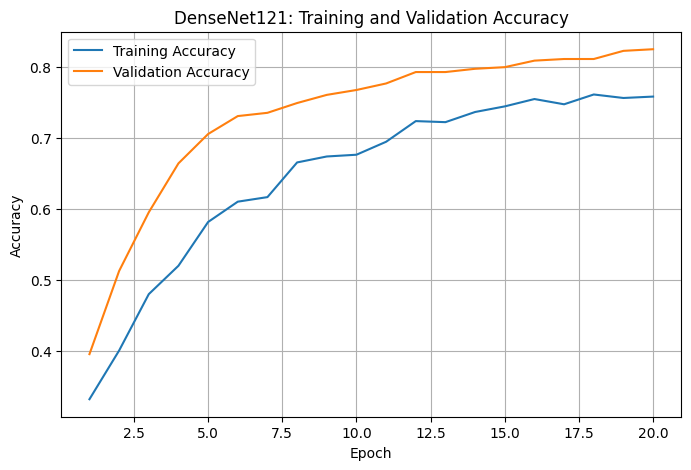

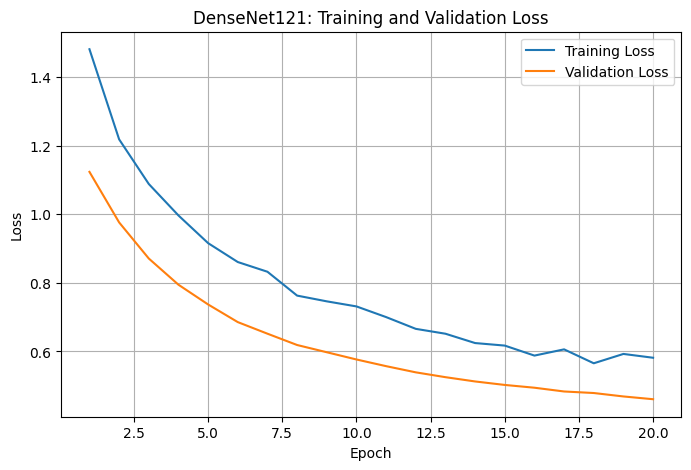

In [ ]:

import matplotlib.pyplot as plt

# Get training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(train_accuracy) + 1)

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracy, label="Training Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.title("DenseNet121: Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("DenseNet121: Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Get the correct labels from the test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Get predictions from DenseNet121
y_prob = model.predict(test_ds, verbose=1)

# Convert predicted probabilities to class labels
y_pred = np.argmax(y_prob, axis=1)

# Calculate test accuracy
accuracy = accuracy_score(y_true, y_pred)

print("\n===== DENSENET121 TEST RESULTS =====")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# Calculate precision, recall and F1-score for each class
class_names = ["Normal", "Stroke", "Tumor"]

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4,
    zero_division=0
))


14/14 ━━━━━━━━━━━━━━━━━━━━ 25s 969ms/step

===== DENSENET121 TEST RESULTS =====
Test Accuracy: 78.62%

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal     0.7037    0.4790    0.5700       119
      Stroke     0.7523    0.8994    0.8193       179
       Tumor     0.8857    0.9051    0.8953       137

    accuracy                         0.7862       435
   macro avg     0.7806    0.7612    0.7615       435
weighted avg     0.7810    0.7862    0.7751       435



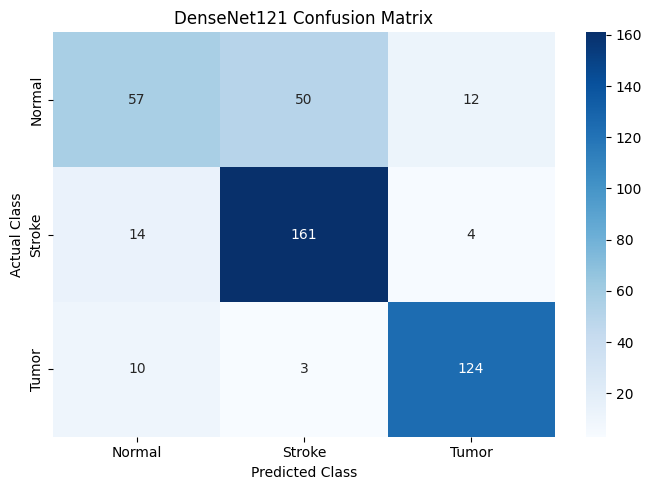

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compare actual labels with predicted labels
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

# Display the confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Stroke", "Tumor"],
    yticklabels=["Normal", "Stroke", "Tumor"]
)

plt.title("DenseNet121 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
from pathlib import Path

# Save fine-tuned results separately
FINE_TUNE_DIR = Path("/content/densenet_finetuned")
FINE_TUNE_DIR.mkdir(parents=True, exist_ok=True)

# Find the DenseNet121 backbone in your existing model
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
    and "densenet" in layer.name.lower()
)

# Freeze the backbone, then unfreeze only its last 30 layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

# Recompile with a low learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best fine-tuned model
checkpoint_ft = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(FINE_TUNE_DIR / "best_densenet121_finetuned.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_ft = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Fine-tune for up to 10 epochs
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint_ft, early_stopping_ft],
    verbose=1
)

print("Fine-tuning completed.")
print("Best model:", FINE_TUNE_DIR / "best_densenet121_finetuned.keras")


Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - accuracy: 0.7719 - loss: 0.5492
Epoch 1: val_loss improved from None to 0.44769, saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras

Epoch 1: finished saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 69s 691ms/step - accuracy: 0.7719 - loss: 0.5539 - val_accuracy: 0.8276 - val_loss: 0.4477
Epoch 2/10
63/64 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.7756 - loss: 0.5654
Epoch 2: val_loss improved from 0.44769 to 0.43037, saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras

Epoch 2: finished saving model to /content/densenet_finetuned/best_densenet121_finetuned.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 132ms/step - accuracy: 0.7817 - loss: 0.5363 - val_accuracy: 0.8391 - val_loss: 0.4304
Epoch 3/10
63/64 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.7868 - loss: 0.5107
Epoch 3: val_loss improved from 0.43037 to 0.41942, saving mod

In [ ]:

import tensorflow as tf
import numpy as np
from sklearn.metrics import accuracy_score, classification_report

# Load the best saved fine-tuned model
fine_tuned_model = tf.keras.models.load_model(
    "/content/densenet_finetuned/best_densenet121_finetuned.keras"
)

# Get actual labels from the test dataset
y_true_ft = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict test classes
y_prob_ft = fine_tuned_model.predict(test_ds, verbose=1)
y_pred_ft = np.argmax(y_prob_ft, axis=1)

# Calculate accuracy
ft_accuracy = accuracy_score(y_true_ft, y_pred_ft)

print("\n===== FINE-TUNED DENSENET121 TEST RESULTS =====")
print(f"Test Accuracy: {ft_accuracy * 100:.2f}%")

# Classification report
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true_ft,
    y_pred_ft,
    labels=[0, 1, 2],
    target_names=["Normal", "Stroke", "Tumor"],
    digits=4,
    zero_division=0
))

# Compare with original test accuracy
original_accuracy = 77.67

print("\n===== ACCURACY COMPARISON =====")
print(f"Original accuracy:    {original_accuracy:.2f}%")
print(f"Fine-tuned accuracy:  {ft_accuracy * 100:.2f}%")
print(f"Difference:           {(ft_accuracy * 100) - original_accuracy:+.2f} percentage points")


14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 962ms/step

===== FINE-TUNED DENSENET121 TEST RESULTS =====
Test Accuracy: 81.38%

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal     0.7711    0.5378    0.6337       119
      Stroke     0.7788    0.9050    0.8372       179
       Tumor     0.8889    0.9343    0.9110       137

    accuracy                         0.8138       435
   macro avg     0.8129    0.7924    0.7940       435
weighted avg     0.8114    0.8138    0.8048       435


===== ACCURACY COMPARISON =====
Original accuracy:    77.67%
Fine-tuned accuracy:  81.38%
Difference:           +3.71 percentage points


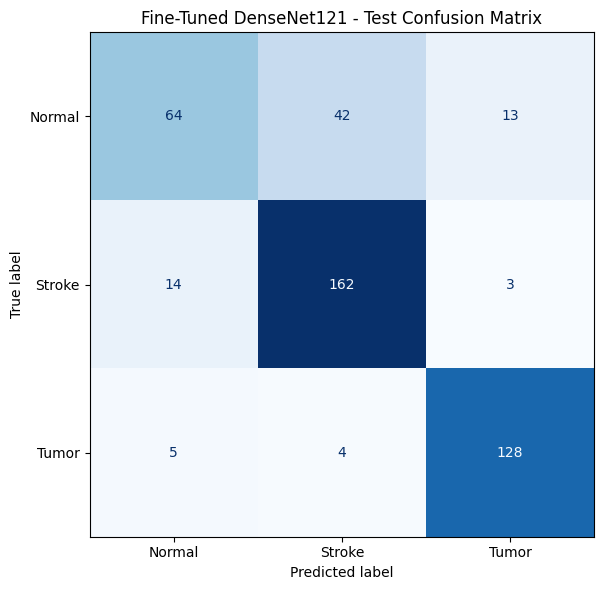

Rows = actual classes; columns = predicted classes.
[[ 64  42  13]
 [ 14 162   3]
 [  5   4 128]]


In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(
    y_true_ft,
    y_pred_ft,
    labels=[0, 1, 2]
)

# Plot it
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Stroke", "Tumor"]
)

fig, ax = plt.subplots(figsize=(7, 6))
display.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("Fine-Tuned DenseNet121 - Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("Rows = actual classes; columns = predicted classes.")
print(cm)


In [ ]:

from collections import Counter
import numpy as np

class_names = ["Normal", "Stroke", "Tumor"]

def count_classes(dataset):
    counts = Counter()

    for _, labels in dataset:
        counts.update(labels.numpy().tolist())

    return counts

train_counts = count_classes(train_ds)
val_counts = count_classes(val_ds)
test_counts = count_classes(test_ds)

print("===== DATASET CLASS DISTRIBUTION =====")

for i, name in enumerate(class_names):
    print(
        f"{name:8s} | "
        f"Train: {train_counts[i]:4d} | "
        f"Validation: {val_counts[i]:4d} | "
        f"Test: {test_counts[i]:4d}"
    )


===== DATASET CLASS DISTRIBUTION =====
Normal   | Train:  553 | Validation:  119 | Test:  119
Stroke   | Train:  835 | Validation:  179 | Test:  179
Tumor    | Train:  637 | Validation:  137 | Test:  137


In [ ]:

import tensorflow as tf
from pathlib import Path

# Load the best fine-tuned model as the starting point
weighted_model = tf.keras.models.load_model(
    "/content/densenet_finetuned/best_densenet121_finetuned.keras"
)

# Keep the same fine-tuning strategy
base_model = next(
    layer for layer in weighted_model.layers
    if isinstance(layer, tf.keras.Model)
    and "densenet" in layer.name.lower()
)

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    layer.trainable = not isinstance(
        layer, tf.keras.layers.BatchNormalization
    )

# Recompile with a low learning rate
weighted_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Class indices: 0 = Normal, 1 = Stroke, 2 = Tumor
class_weights = {
    0: 1.3,  # Give Normal errors more importance
    1: 1.0,
    2: 1.0
}

save_dir = Path("/content/densenet_class_weighted")
save_dir.mkdir(parents=True, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(save_dir / "best_class_weighted.keras"),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

# Train using training and validation data only
weighted_history = weighted_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("Class-weighted training completed.")
print("Saved model:", save_dir / "best_class_weighted.keras")


Epoch 1/8
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - accuracy: 0.8124 - loss: 0.5099
Epoch 1: val_loss improved from None to 0.34970, saving model to /content/densenet_class_weighted/best_class_weighted.keras

Epoch 1: finished saving model to /content/densenet_class_weighted/best_class_weighted.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 64s 636ms/step - accuracy: 0.8198 - loss: 0.4901 - val_accuracy: 0.8851 - val_loss: 0.3497
Epoch 2/8
63/64 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8252 - loss: 0.4798
Epoch 2: val_loss improved from 0.34970 to 0.34706, saving model to /content/densenet_class_weighted/best_class_weighted.keras

Epoch 2: finished saving model to /content/densenet_class_weighted/best_class_weighted.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 133ms/step - accuracy: 0.8252 - loss: 0.4696 - val_accuracy: 0.8805 - val_loss: 0.3471
Epoch 3/8
63/64 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.8277 - loss: 0.4827
Epoch 3: val_loss improved from 0.34706 to 0.34130, saving model to /cont

In [ ]:

import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

# Load the best class-weighted model
weighted_model = tf.keras.models.load_model(
    "/content/densenet_class_weighted/best_class_weighted.keras"
)

# Get actual validation labels
y_val_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

# Predict validation classes
y_val_prob = weighted_model.predict(val_ds, verbose=1)
y_val_pred = np.argmax(y_val_prob, axis=1)

# Calculate validation accuracy
val_accuracy = accuracy_score(y_val_true, y_val_pred)

print("\n===== CLASS-WEIGHTED VALIDATION RESULTS =====")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

# Show precision, recall and F1-score for every class
print("\n===== VALIDATION CLASSIFICATION REPORT =====")
print(classification_report(
    y_val_true,
    y_val_pred,
    labels=[0, 1, 2],
    target_names=["Normal", "Stroke", "Tumor"],
    digits=4,
    zero_division=0
))


14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 955ms/step

===== CLASS-WEIGHTED VALIDATION RESULTS =====
Validation Accuracy: 89.20%

===== VALIDATION CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Normal     0.8571    0.7563    0.8036       119
      Stroke     0.8515    0.9609    0.9029       179
       Tumor     0.9844    0.9197    0.9509       137

    accuracy                         0.8920       435
   macro avg     0.8977    0.8790    0.8858       435
weighted avg     0.8949    0.8920    0.8909       435



14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 942ms/step

===== CLASS-WEIGHTED TEST RESULTS =====
Test Accuracy: 83.45%

===== PRECISION, RECALL AND F1-SCORE =====
              precision    recall  f1-score   support

      Normal     0.7935    0.6134    0.6919       119
      Stroke     0.8081    0.8939    0.8488       179
       Tumor     0.8966    0.9489    0.9220       137

    accuracy                         0.8345       435
   macro avg     0.8327    0.8187    0.8209       435
weighted avg     0.8319    0.8345    0.8289       435



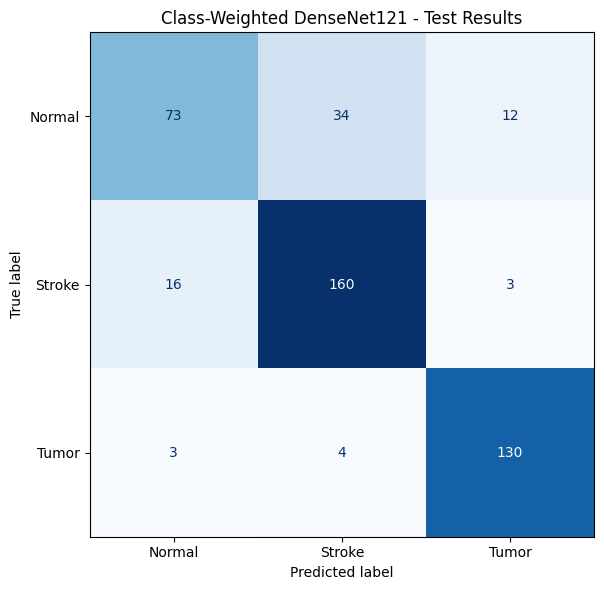

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the saved class-weighted model
final_model = tf.keras.models.load_model(
    "/content/densenet_class_weighted/best_class_weighted.keras"
)

class_names = ["Normal", "Stroke", "Tumor"]

# Get actual test labels
y_test_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict test images
y_test_prob = final_model.predict(test_ds, verbose=1)
y_test_pred = np.argmax(y_test_prob, axis=1)

# Calculate test accuracy
test_accuracy = accuracy_score(y_test_true, y_test_pred)

print("\n===== CLASS-WEIGHTED TEST RESULTS =====")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Classification report
print("\n===== PRECISION, RECALL AND F1-SCORE =====")
print(classification_report(
    y_test_true,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
plt.title("Class-Weighted DenseNet121 - Test Results")
plt.tight_layout()
plt.show()


In [ ]:

from google.colab import files
from pathlib import Path

model_path = Path(
    "/content/densenet_class_weighted/best_class_weighted.keras"
)

if model_path.exists():
    print(f"Model size: {model_path.stat().st_size / (1024**2):.2f} MB")
    files.download(str(model_path))
else:
    print("Model file not found. Check the saved model path.")


Model size: 33.13 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>